This script will follow an outline proposed in a notebook associated with the dataset we are looking to fine tune our models on found [HERE](https://www.kaggle.com/code/mohitagarwal17/dog-emotion-classifier-90-accuracy).

# Reproducible model script

This notebook is intended for use by our sprint 2 group. The aim is to produce a standardised script to use across laptops in order to train, test and extract evaluation metrics for the various fine tuned models. We hope that this script can be ran with a simple

```
###############
## CHANGE ME ##
###############
```
line which will determine the pretrained model which we will then fine tune.

## Procedure

Note that since the models we are training are going to be so varied in size, the tuning and training regime suitable for one model may be very unsuitable for another. We choose the following approach to combat this:

1. Assign to each group member a model.
2. Independently research in-order to find a suitable training regime for assigned model.
3. Implement training regime and observe performance on withheld test data.
4. Compare preliminary results, choose model with most promising results, then pool resources to further research and implement best training regime for chosen model.

## Controls

Since we will are first choosing a final model to investigate based on it's performance on withheld data, and then further fine tuning siad model using the same data we have to be careful about data leakage. To the end of protecting against this we will use the following measures:

* Take a 90/10 development-test split of the dataset.
* The development data will be used for initial model tests as well as for learning and fine tuning of final model.
* Test data is used only for final test of tuned final model.

To ensure repeatability in the initial model selection phase, we will pay careful consideration to setting the same random seed across notebooks trialing various models. This will ensure built in 'random' methods used to obtain train, validation, test data. This allows each model to be tested on the same test data etc.

### NOTE TO SELF
Jonty's models to for init tune:
Resnet18 -
Alexnet -75%
Squeezenet -80%
Densenet -90%



In [9]:
import kagglehub

from pathlib import Path
from fastai.vision.all import *

from sklearn.model_selection import train_test_split
from collections import Counter

import torch

import matplotlib.pyplot as plt
import zipfile
from contextlib import redirect_stdout
from google.colab import files as colab_files

import shutil

print(f'Finished loading packages')

Finished loading packages


In [10]:
# IMPORTANT: RUN THIS CELL IN ORDER TO IMPORT YOUR KAGGLE DATA SOURCES,
# THEN FEEL FREE TO DELETE THIS CELL.

danielshanbalico_dog_emotion_path = kagglehub.dataset_download('danielshanbalico/dog-emotion')
print(danielshanbalico_dog_emotion_path)
mohitagarwal17_dog_img_path = kagglehub.dataset_download('mohitagarwal17/dog-img')
mohitagarwal17_dog_emotion_classifier_89_accuracy_other_default_1_path = kagglehub.model_download('mohitagarwal17/dog-emotion-classifier-89-accuracy/Other/default/1')

Using Colab cache for faster access to the 'dog-emotion' dataset.
/kaggle/input/dog-emotion
Using Colab cache for faster access to the 'dog-img' dataset.


In [11]:
searches = 'angry','happy','relaxed','sad'
path = Path(danielshanbalico_dog_emotion_path)

# Load the CSV containing the selected filenames
csv_url = "https://raw.githubusercontent.com/Sincanator/Group-Sprint-2/refs/heads/main/Data/emotion_classifier_data_from_kaggle/development_split.csv"
df = pd.read_csv(csv_url)

# Create files list using only filenames in CSV
files = [path / filename for filename in df["filename"]]

print(f"Number of images in subset: {len(files)}")

Number of images in subset: 3600


In [12]:
# Create train test split
train_files, test_files = train_test_split(
    files,
    test_size=0.15,
    random_state=42,
    stratify=[f.parent.name for f in files] # <- Addition to notebook
    )

print(len(train_files))
print(len(test_files))

# Checking the class distribution in data split
print("Training:", Counter(f.parent.name for f in train_files))
print("Testing:", Counter(f.parent.name for f in test_files))

# optimise densenet

3060
540
Training: Counter({'relaxed': 765, 'happy': 765, 'angry': 765, 'sad': 765})
Testing: Counter({'happy': 135, 'angry': 135, 'sad': 135, 'relaxed': 135})


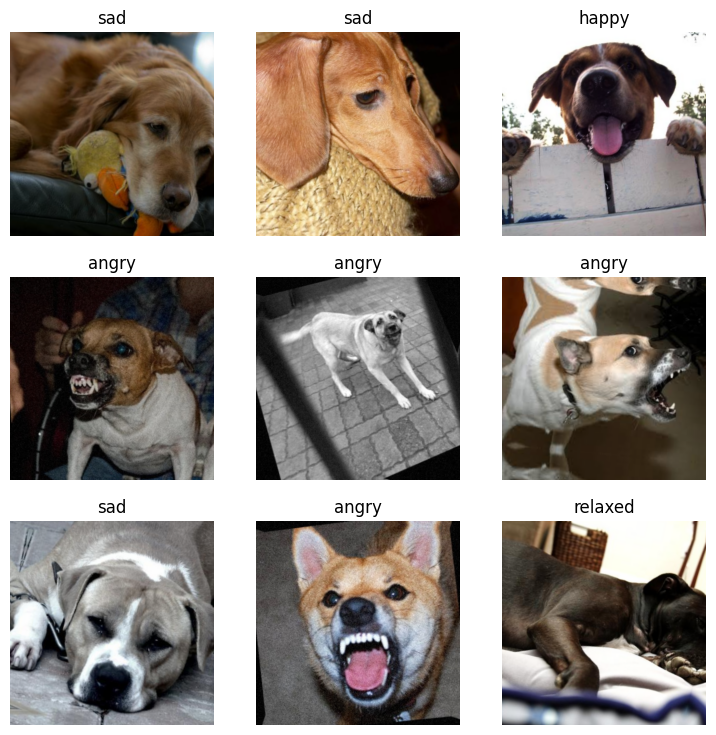

In [13]:
from sklearn.metrics import label_ranking_average_precision_score
dls = DataBlock(
    blocks=(ImageBlock, CategoryBlock),
    get_items=noop,
    splitter=RandomSplitter(valid_pct=0.2, seed=42), # generates validation set 20% of train
    get_y=parent_label, # gets labesl
    item_tfms=[Resize(400, method='pad', pad_mode='reflection')], # resizes to 400 x 400 with padding using reflection padding mode. Done since squishing features may make harder to read expression
    batch_tfms=aug_transforms(mult=1.0,
                              do_flip=True,
                              flip_vert=False,
                              max_rotate=15.0,
                              min_zoom=1.0,
                              max_zoom=1.1,
                              max_lighting=0.2,
                              max_warp=0.1) # augmentation done on the fly and in place rather than statically, changes for each training epoch to reduce overfitting
).dataloaders(train_files, bs=16) # batch size of 16 is changed from 56 since crahsed t4gpu usage limits, train data is of size 4000 * 0.85 * 0.8 = 2720 (2720 / 40 = 68)

dls.show_batch()

learn = vision_learner(dls,

                       #######################
                       ### MODEL TO CHANGE ###
                       ######## BELOW ########
                       #######################



                       densenet121,
                       opt_func=Adam,

                       loss_func=CrossEntropyLossFlat(), #looked to replace normal cross entropy with label smoothed due to some dodgy labels, but didnt improve accuracy
                       metrics=error_rate,
                       wd=0.01).to_fp16() # using transfer learning from pretrained alexnet.
                       # largish wd of 0.05 for alexnet to combat overfitting




In [14]:
if torch.cuda.is_available():
    print("GPU available:", torch.cuda.get_device_name(0))
    print("CUDA version:", torch.version.cuda)
else:
    print("No GPU available. Using CPU.")



GPU available: Tesla T4
CUDA version: 13.0


<div></div>

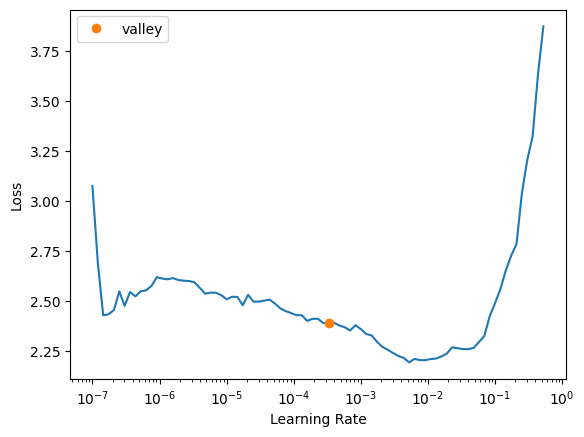

In [15]:
lrs = learn.lr_find()


In [16]:
lrs.valley


0.0003311311302240938

epoch,train_loss,valid_loss,error_rate,time
0,1.441698,1.214750,0.315359,01:09


epoch,train_loss,valid_loss,error_rate,time
0,0.889949,1.113845,0.357843,01:10
1,0.758809,0.548517,0.209150,01:09
2,0.439969,0.391637,0.130719,01:10
3,0.260712,0.341872,0.129085,01:10


epoch,train_loss,valid_loss,error_rate,time
0,0.234263,0.338151,0.119281,01:10
1,0.257220,0.413885,0.135621,01:10
2,0.166733,0.375751,0.132353,01:09
3,0.114415,0.331052,0.102941,01:09
4,0.086674,0.321477,0.116013,01:10


epoch,train_loss,valid_loss,error_rate,time
0,0.091559,0.339803,0.117647,01:09
1,0.067119,0.334542,0.116013,01:08


epoch,train_loss,valid_loss,error_rate,time
0,0.055883,0.341420,0.112745,01:08


<Axes: title={'center': 'learning curve'}, xlabel='steps', ylabel='loss'>

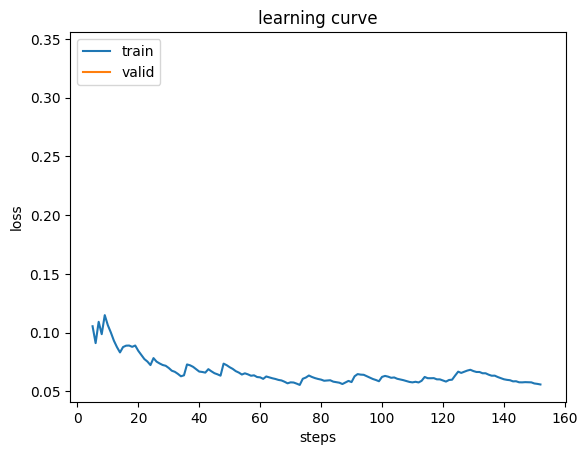

In [17]:



###########################
##### LEARNING REGIME #####
### CHANGE STUFF BELOW! ###
###########################



learn.fine_tune(4, base_lr=1e-2) # finetune is built in to tune pretrained models, it uses adaptive lr. for 4 epochs trains class head, then whole model for 1 epoch

learn.unfreeze()

learn.fit_one_cycle(5, lr_max=1e-4)

learn.fit_one_cycle(2, lr_max=1e-5)

learn.fit_one_cycle(1, lr_max=1e-6)

learn.recorder.plot_loss() # added to plot the loss


In [18]:
test_dl = dls.test_dl(test_files, with_labels=True)
loss, err = learn.validate(dl=test_dl)
accuracy = (1-err)*100
print(f"Test Images: {len(test_files)}")
print(f"Correct Predictions: {round(accuracy*len(test_files)/100)}")
print(f"Incorrect Predictions: {len(test_files)-round(accuracy*len(test_files)/100)}")
print(f"Accuracy: {accuracy:.2f}%")

Test Images: 540
Correct Predictions: 483
Incorrect Predictions: 57
Accuracy: 89.44%


In [19]:
next(learn.model.parameters()).device

##############################
### PUT MODEL NAME IN PATH ###
##############################

save_path = Path('/content/dog_emotion_model_resnet50_final.pkl')

# Export the trained model
learn.cpu()
learn.export(save_path)

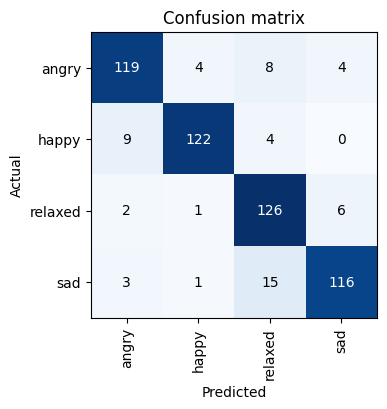

In [20]:
interp = ClassificationInterpretation.from_learner(
    learn,
    dl=test_dl)
interp.plot_confusion_matrix(figsize=(4,4))

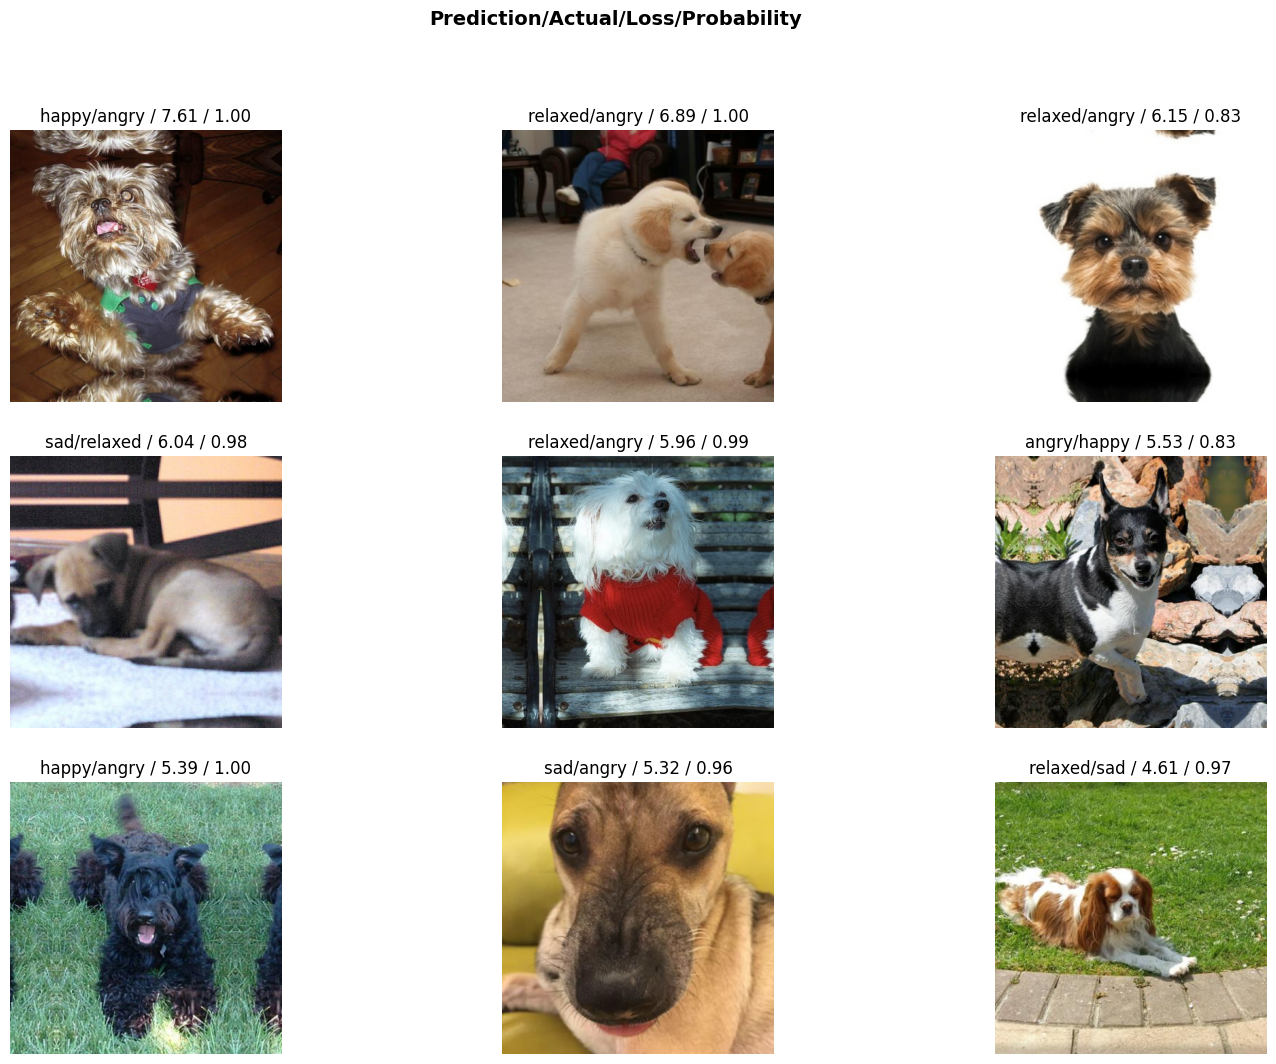

In [21]:
interp.plot_top_losses(9, figsize=(18,12))

Alexnet
Potential issue: Of the top 36 losses, at least 10 of them are due to mislabelled data in dataset according to animal behaviourist (TBC). This it is slightly tricky to say with certainty that the model is performing as accuracy says it is. Equally, the validation loss decreases with each epoch so this is promising. Research suggests that using label_smoothing entropy as loss func will perhaps allow better training. We tried this experiment and accuracy decreased from 72% to 67%. Further, inspection of top losses still suggests that the highest losses occured with potentially mislabelled data. As such we will not look to continue to research into a solution for this issue.

In [22]:
interp.print_classification_report()

              precision    recall  f1-score   support

       angry       0.89      0.88      0.89       135
       happy       0.95      0.90      0.93       135
     relaxed       0.82      0.93      0.88       135
         sad       0.92      0.86      0.89       135

    accuracy                           0.89       540
   macro avg       0.90      0.89      0.89       540
weighted avg       0.90      0.89      0.89       540



results of form true | predicted


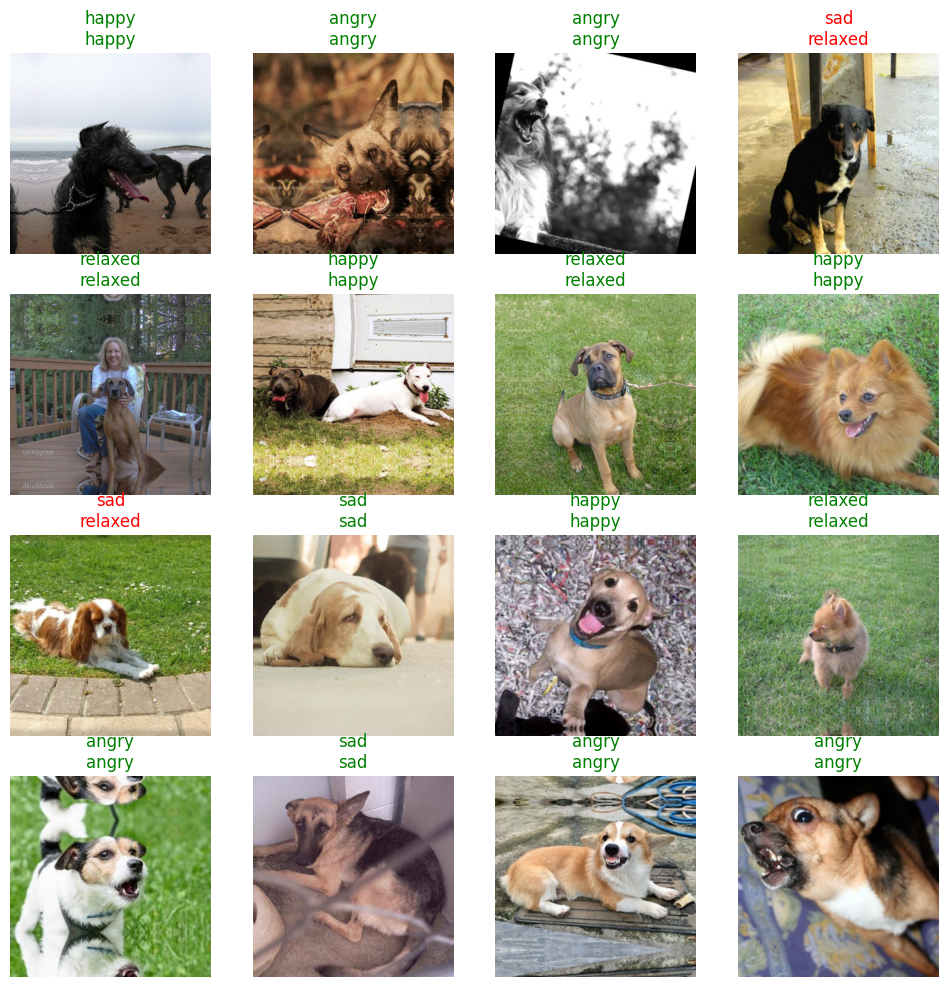

In [23]:
print(f'results of form true | predicted')
interp.show_results(idxs=list(range(16)))

In [24]:
# Create results folder

#############################
### CHANGE DIRECTORY NAME ###
#############################
results_dir = Path('/content/resnet50_final_results')
results_dir.mkdir(exist_ok=True)

# 1. Copy exported model into results folder
shutil.copy(save_path, results_dir / save_path.name)

# 2. Save confusion matrix
interp.plot_confusion_matrix(figsize=(4, 4))
plt.savefig(results_dir / 'confusion_matrix.png',
            bbox_inches='tight', dpi=200)
plt.close('all')

# 3. Save top 9 losses
interp.plot_top_losses(9, figsize=(10, 7))
plt.savefig(results_dir / 'top_losses.png',
            bbox_inches='tight', dpi=200)
plt.close('all')

# 4. Save classification report
with open(results_dir / 'classification_report.txt', 'w') as f:
    with redirect_stdout(f):
        interp.print_classification_report()

# 5. Save 16 example predictions
interp.show_results(idxs=list(range(16)))
plt.savefig(results_dir / 'example_predictions.png',
            bbox_inches='tight', dpi=200)
plt.close('all')

# 6. Create ZIP
zip_path = Path('/content/resnet50_final_results.zip')

with zipfile.ZipFile(zip_path, 'w', zipfile.ZIP_DEFLATED) as zipf:
    for file in results_dir.iterdir():
        if file.is_file():
            zipf.write(file, arcname=file.name)

# 7. Download
colab_files.download(str(zip_path))

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>